In [2]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split


In [3]:
# load handwritten digits dataset 
digits = load_digits() 

# extract images and corresponding labels 
images = digits.images 
x = digits.data 
y = digits.target 

print("dataset loaded successfully") 

print("Image shape: ", images.shape) 
print("feature matrix shape: ", x.shape)
print("labels shape: ", y.shape)

dataset loaded successfully
Image shape:  (1797, 8, 8)
feature matrix shape:  (1797, 64)
labels shape:  (1797,)


- 1797 --> total handwritten digit samples 
- 8 * 8 --> dimensions of each handwritten image 
- 64 --> number of features in an image 
- 1797 labels --> corresponding digit classification (0-9) 

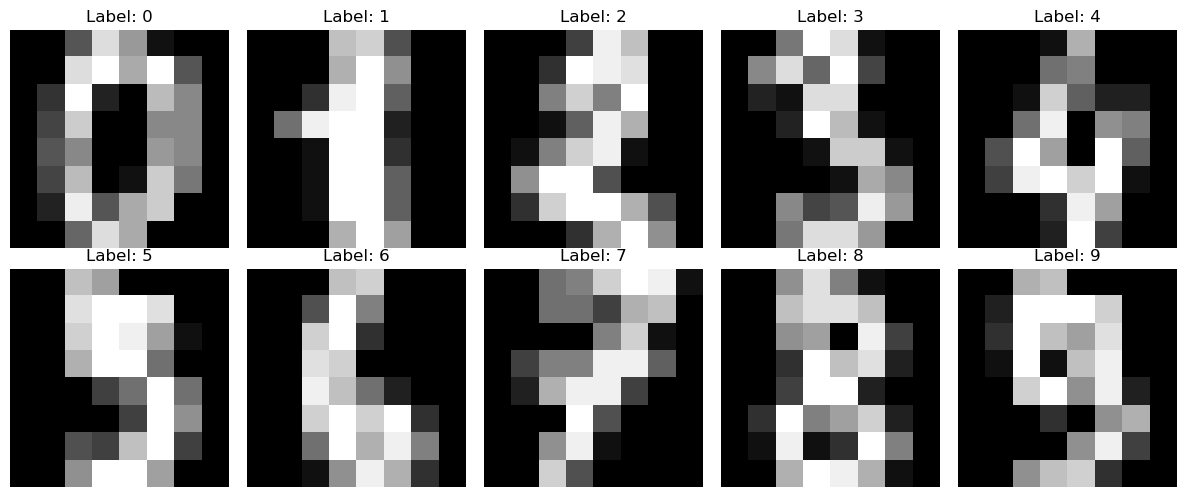

In [4]:
# visualize some samples to understand the dataset 
fig, axes = plt.subplots(2, 5, figsize=(12,5)) 

for i, ax in enumerate(axes.flat):

    ax.imshow(images[i], cmap='gray') 
    ax.set_title(f"Label: {y[i]}") 
    ax.axis("off")

plt.tight_layout() 
plt.show()

In [5]:
# extract features --> we will use flattening 

# flatten each 8*8 image into a  64 dim vector 

X = images.reshape(images.shape[0], 64) 

print("feature extraction completed") 

print("new feature matrix shape: ", X.shape) 

# display first sample 
print("\nFirst sample features: ")
print(X[0]) 

print("\nCorresponding label: ", y[0])

feature extraction completed
new feature matrix shape:  (1797, 64)

First sample features: 
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]

Corresponding label:  0


In [8]:
# dataset pre-processing and normalization 
# pixel intensities range --> 0 and 16 

print("Min pixel intensity: ", X.min()) 
print("Max pixel intensity: ", X.max()) 

print("Data type: ", X.dtype)

# convert pixel intensities into unsinged 8-bit integers 

X = X.astype(np.uint8) 

print("Converted data type: ", X.dtype) 
print("Min: ", X.min()) 
print("Max: ", X.max())

Min pixel intensity:  0.0
Max pixel intensity:  16.0
Data type:  float64
Converted data type:  uint8
Min:  0
Max:  16


# Why not apply StandardScaler?
- For our FPGA implementation, retaining the original pixel intensities is recommneded.

## Reasons:
1. All 64 features represent pixel intensities on the same scale.
2. Euclidean distance works directly with these values.
3. Integer arithmetic is simpler and more hardware-friendly.
4. We can use unsigned 8-bit integers to store pixel values.

# Advantage due to feature-matrix conversion 
- Each pixel now requires only 8 bits instead of 64 bits (float64)

In [12]:
# do train_test_split --> 0.2 for test 
# also, i am using stratify = y to maintain approx the same class distribution in both the datasets 

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")

print("\nTraining dataset:")
print("Features:", X_train.shape)
print("Labels:", y_train.shape)

print("\nTesting dataset:")
print("Features:", X_test.shape)
print("Labels:", y_test.shape)

Dataset splitting completed!

Training dataset:
Features: (1437, 64)
Labels: (1437,)

Testing dataset:
Features: (360, 64)
Labels: (360,)


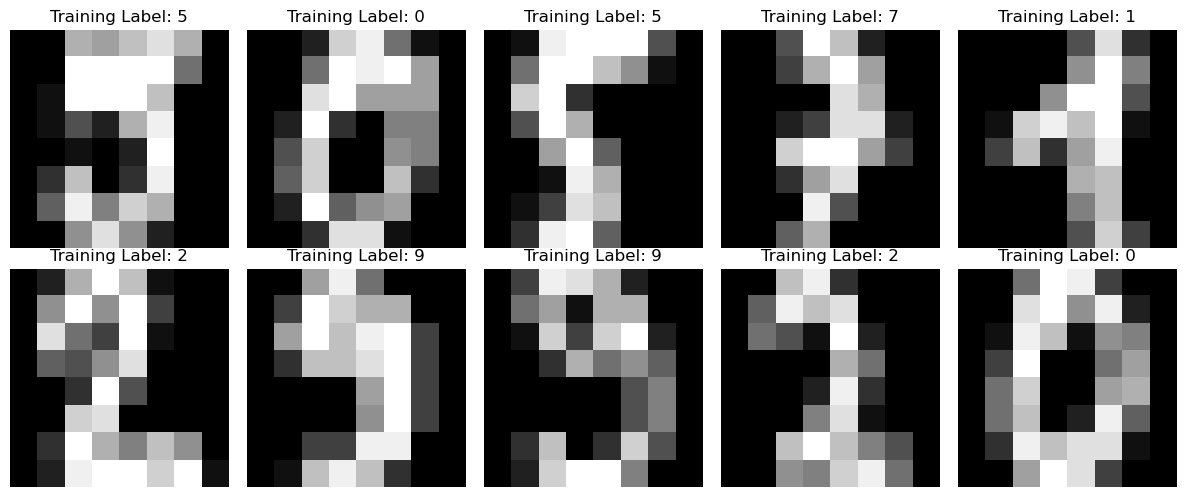

In [13]:
# visualize training samples 
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    ax.imshow(X_train[i].reshape(8, 8), cmap='gray')

    ax.set_title(f"Training Label: {y_train[i]}")

    ax.axis('off')

plt.tight_layout()
plt.show()

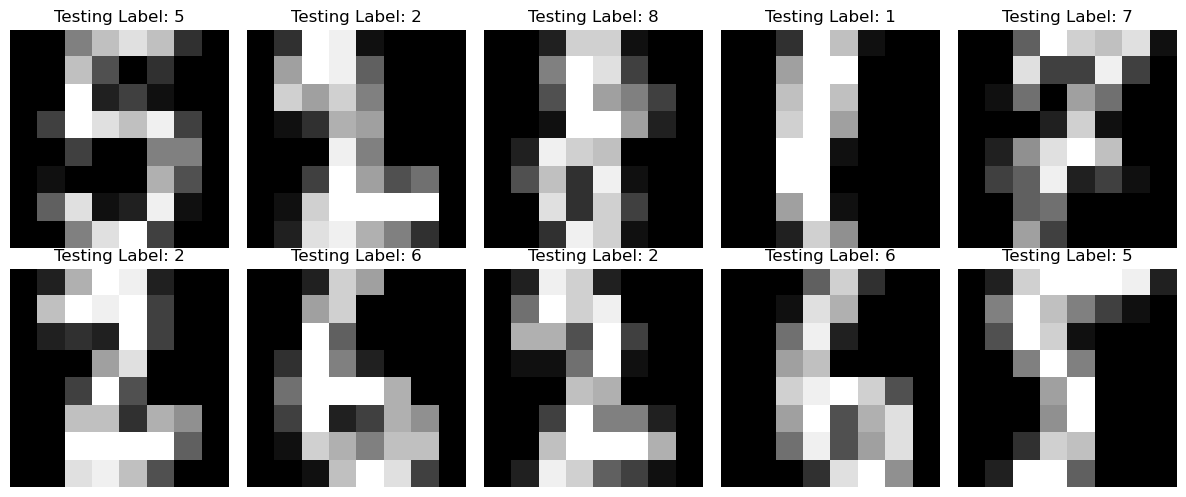

In [14]:
# visualize testing samples 
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    ax.imshow(X_test[i].reshape(8, 8), cmap='gray')

    ax.set_title(f"Testing Label: {y_test[i]}")

    ax.axis('off')

plt.tight_layout()
plt.show()

In [15]:
# verify class distribution 
# - we have 10 classes --> so we are verifying that training and testing datasets contain samples from all classes 

print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training class distribution:
0    142
1    146
2    142
3    146
4    145
5    145
6    145
7    143
8    139
9    144
Name: count, dtype: int64

Testing class distribution:
0    36
1    36
2    35
3    37
4    36
5    37
6    36
7    36
8    35
9    36
Name: count, dtype: int64


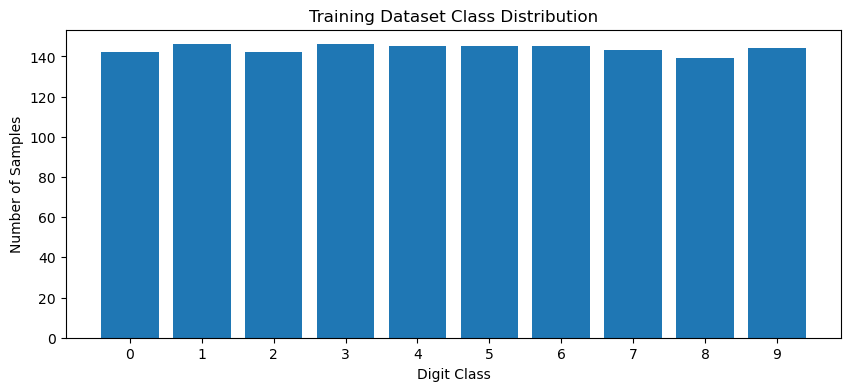

In [16]:
# visualize the distribution 
plt.figure(figsize=(10, 4))

plt.hist(y_train, bins=np.arange(-0.5, 10.5, 1), rwidth=0.8)

plt.xticks(range(10))
plt.xlabel("Digit Class")
plt.ylabel("Number of Samples")
plt.title("Training Dataset Class Distribution")

plt.show()

In [17]:
# save the pre-processed datasets 

In [18]:
# Save all four datasets

np.save("train_data.npy", X_train)
np.save("train_labels.npy", y_train)

np.save("test_data.npy", X_test)
np.save("test_labels.npy", y_test)

print("All datasets saved successfully!")

All datasets saved successfully!


# Start building KNN 

In [ ]:
# import required libraries 
import time 

from sklearn.metrics import (
    accuracy_score, 
    confusion_matrix, 
    classification_report, 
    ConfusionMatrixDisplay 
)

print("all libraries imported successfully")

In [21]:
# verify the prepared dataset 
print("========== DATASET INFORMATION ==========")

print("Training Features:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Features:", X_test.shape)
print("Testing Labels:", y_test.shape)

print("\nFeature datatype:", X_train.dtype)
print("Label datatype:", y_train.dtype)

print("\nNumber of classes:", len(np.unique(y_train)))

========== DATASET INFORMATION ==========
Training Features: (1437, 64)
Training Labels: (1437,)
Testing Features: (360, 64)
Testing Labels: (360,)

Feature datatype: uint8
Label datatype: int64

Number of classes: 10


In [22]:
# implement the euclidean distance calculation 
# - i am eliminating the square root bcz it does not affect the ordering of distances 

def calculate_distance(test_sample, training_samples):

    # Convert to signed integer to avoid uint8 subtraction overflow
    test_sample = test_sample.astype(np.int32)
    training_samples = training_samples.astype(np.int32)

    # Calculate difference between test and training samples
    differences = training_samples - test_sample

    # Square each difference and sum across 64 features
    distances = np.sum(differences ** 2, axis=1)

    return distances

In [23]:
# Test the function 
# Select one test sample
sample = X_test[0]

# Calculate its distance from every training sample
distances = calculate_distance(sample, X_train)

print("Number of calculated distances:", len(distances))

print("\nFirst 10 distances:")
print(distances[:10])

print("\nMinimum distance:", distances.min())
print("Maximum distance:", distances.max())

Number of calculated distances: 1437

First 10 distances:
[2030 1922 2787 3337 2711 2892 1738 1179 2829 1756]

Minimum distance: 316
Maximum distance: 4433


In [25]:
# Implement K-NN selection 
# - after calculating all distances, we need to select the k smallest distances 
# - i am using Numpy's argpartition() to efficiently identify k nearest neighbors without sorting the entire dataset 

def select_k_nearest(distances, k):

    # Find indices of k smallest distances
    nearest_indices = np.argpartition(distances, k-1)[:k]

    # Sort only the selected k neighbors by distance
    nearest_indices = nearest_indices[
        np.argsort(distances[nearest_indices])
    ]

    return nearest_indices

In [26]:
# test the function 
k = 5

nearest_indices = select_k_nearest(distances, k)

print("Nearest Neighbor Indices:")
print(nearest_indices)

print("\nCorresponding Distances:")
print(distances[nearest_indices])

print("\nCorresponding Labels:")
print(y_train[nearest_indices])

Nearest Neighbor Indices:
[ 910  151 1258  368  534]

Corresponding Distances:
[316 357 422 425 449]

Corresponding Labels:
[5 5 5 5 5]


In [27]:
# implement majority voting --> also handle ties by selecting the class whose nearest neighbor has the smallest distance 
def majority_voting(nearest_indices, distances, training_labels):

    # Obtain labels of nearest neighbors
    nearest_labels = training_labels[nearest_indices]

    # Count votes for each class (0-9)
    votes = np.bincount(nearest_labels, minlength=10)

    # Find maximum number of votes
    max_votes = np.max(votes)

    # Identify classes having maximum votes
    candidate_classes = np.where(votes == max_votes)[0]

    # Handle ties using nearest neighbor distance
    if len(candidate_classes) > 1:

        for idx in nearest_indices:

            label = training_labels[idx]

            if label in candidate_classes:
                predicted_class = label
                break

    else:
        predicted_class = candidate_classes[0]

    return predicted_class

In [28]:
# test the function 
predicted_class = majority_voting(
    nearest_indices,
    distances,
    y_train
)

print("Actual Class:", y_test[0])
print("Predicted Class:", predicted_class)

Actual Class: 5
Predicted Class: 5


In [29]:
# Implement the complete KNN classifier by combining all the 3 components into a single function 

def knn_classifier(test_sample, training_samples, training_labels, k):

    # Step 1: Calculate distances
    distances = calculate_distance(
        test_sample,
        training_samples
    )

    # Step 2: Select k nearest neighbors
    nearest_indices = select_k_nearest(
        distances,
        k
    )

    # Step 3: Perform majority voting
    predicted_class = majority_voting(
        nearest_indices,
        distances,
        training_labels
    )

    return predicted_class

In [ ]:
# testing using 1 test sample 
k = 5

prediction = knn_classifier(
    X_test[0],
    X_train,
    y_train,
    k
)

print("Actual Digit:", y_test[0])
print("Predicted Digit:", prediction)

# both values match means, your classifier has correctly classified that sample 

Actual Digit: 5
Predicted Digit: 5


In [32]:
# predict for all the 360 test samples --> execute our KNN classifier for the entire test set 
k = 5

predictions = []

start_time = time.perf_counter()

for i in range(len(X_test)):

    predicted_class = knn_classifier(
        X_test[i],
        X_train,
        y_train,
        k
    )

    predictions.append(predicted_class)

end_time = time.perf_counter()

predictions = np.array(predictions)

execution_time = end_time - start_time

print("Classification completed!")

print("Total testing samples:", len(X_test))
print("Total predictions:", len(predictions))

print("Execution time:", round(execution_time, 4), "seconds")

Classification completed!
Total testing samples: 360
Total predictions: 360
Execution time: 0.0891 seconds


In [33]:
# calculate classification accuracy --> correct pred / total pred * 100 
accuracy = accuracy_score(y_test, predictions)

print("========== CLASSIFICATION RESULTS ==========")

print("Total Testing Samples:", len(y_test))

print("Correct Predictions:",
      np.sum(y_test == predictions))

print("Incorrect Predictions:",
      np.sum(y_test != predictions))

print("Classification Accuracy:",
      round(accuracy * 100, 2), "%")

print("Execution Time:",
      round(execution_time, 4), "seconds")

========== CLASSIFICATION RESULTS ==========
Total Testing Samples: 360
Correct Predictions: 354
Incorrect Predictions: 6
Classification Accuracy: 98.33 %
Execution Time: 0.0891 seconds


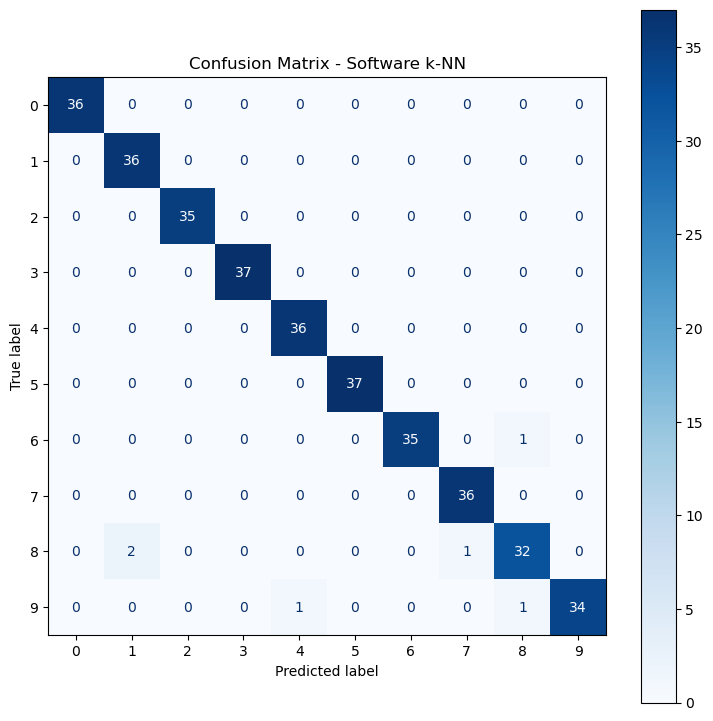

In [34]:
# generate confusion matrix 
cm = confusion_matrix(y_test, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(9, 9))

disp.plot(
    cmap='Blues',
    ax=ax,
    values_format='d'
)

plt.title("Confusion Matrix - Software k-NN")
plt.show()

In [36]:
# generate classification report 
print(
    classification_report(
        y_test,
        predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      1.00      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.94      0.91      0.93        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [ ]:
# hyperparameter tuning with different values of k 
# i am using {1,3,5,7,9} 

k_values = [1, 3, 5, 7, 9]

results = []

for k in k_values:

    predictions_k = []

    start = time.perf_counter()

    for i in range(len(X_test)):

        pred = knn_classifier(
            X_test[i],
            X_train,
            y_train,
            k
        )

        predictions_k.append(pred)

    end = time.perf_counter()

    acc = accuracy_score(y_test, predictions_k)

    results.append({
        "K": k,
        "Accuracy (%)": round(acc * 100, 2),
        "Execution Time (s)": round(end - start, 4)
    })

results_df = pd.DataFrame(results)

print(results_df)


   K  Accuracy (%)  Execution Time (s)
0  1         98.61              0.1093
1  3         98.61              0.1250
2  5         98.33              0.1510
3  7         98.33              0.0780
4  9         98.33              0.0728


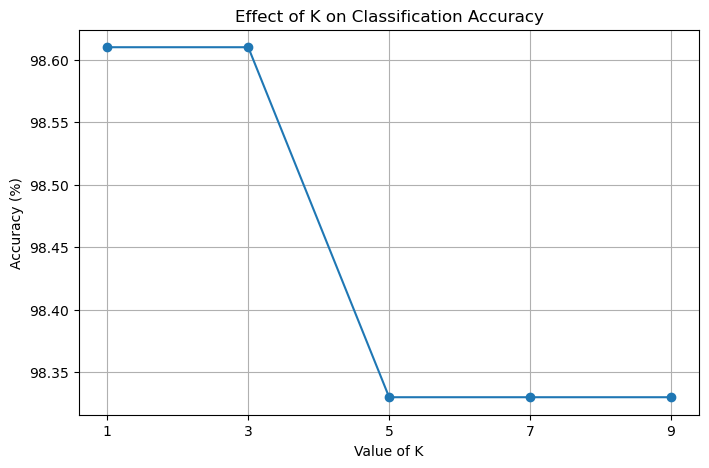

In [ ]:
# visualize the accuracy 
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Accuracy (%)"],
    marker='o'
)

plt.xlabel("Value of K")
plt.ylabel("Accuracy (%)")

plt.title("Effect of K on Classification Accuracy")

plt.xticks(k_values)
plt.grid(True)

plt.show()

# from here, i can say that, choosing k = 3 makes sense 


In [39]:
# save the software classification results  
# - I am saving these predictions and evaluation results becuase we will eventually compare them with FPGA predictions 

# Save predictions
np.save("software_predictions.npy", predictions)

# Save results table
results_df.to_csv(
    "software_knn_results.csv",
    index=False
)

print("Software k-NN results saved successfully!")

Software k-NN results saved successfully!
